# Statistical Analytic Methods
#### Prof. KKIM, Yonsei University
### LEC11. Regression

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Regression with Boston Housing Data

CRIM - per capita crime rate by town

ZN - proportion of residential land zoned for lots over 25,000 sq.ft.

INDUS - proportion of non-retail business acres per town.

CHAS - Charles River dummy variable (1 if tract bounds river; 0 otherwise)

NOX - nitric oxides concentration (parts per 10 million)

RM - average number of rooms per dwelling

AGE - proportion of owner-occupied units built prior to 1940

DIS - weighted distances to five Boston employment centres

RAD - index of accessibility to radial highways

TAX - full-value property-tax rate per $10,000

PTRATIO - pupil-teacher ratio by town

B - 1000(Bk - 0.63)^2 where Bk is the proportion of blacks by town

LSTAT - % lower status of the population
MEDV - Median value of owner-occupied homes in $1000's

In [6]:
import pandas as pd
import seaborn as sns
import numpy as np
from statsmodels.formula.api import ols

housing_df = pd.read_csv('/content/drive/MyDrive/[YU]/[Lecture]/[SAM]/01_SAM_Practice/SAM_LEC11/HousingData.csv')
housing_df

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0.0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,NaN,22.4
502,0.04527,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0.0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0


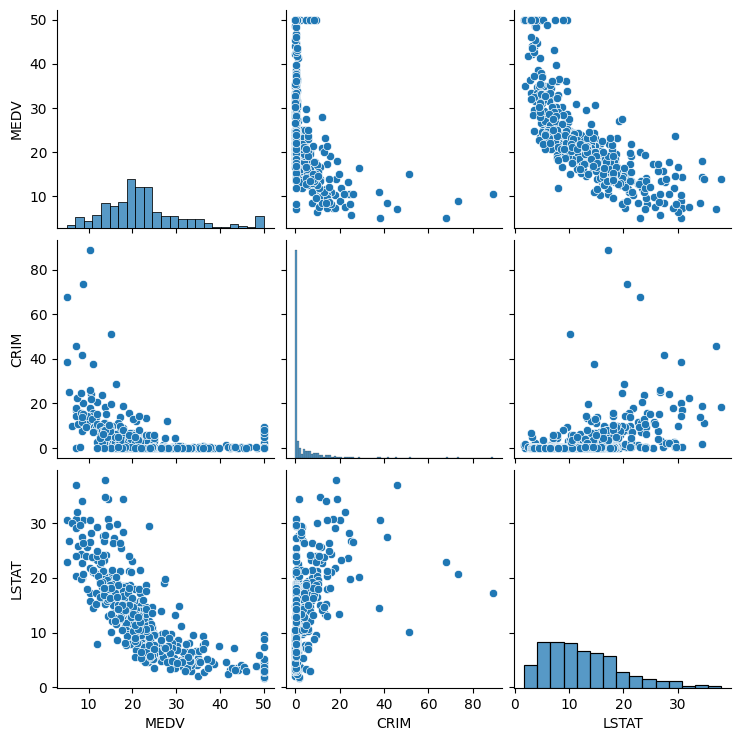

In [ ]:
sns.pairplot(housing_df[['MEDV','CRIM','LSTAT']])

### Simple Regression

In [ ]:
statsOLSModel = ols('MEDV ~ CRIM', data=housing_df)
statsOLSModel

In [ ]:
statsOLSModel_res = statsOLSModel.fit()
statsOLSModel_res

In [ ]:
print(statsOLSModel_res.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.153
Model:                            OLS   Adj. R-squared:                  0.151
Method:                 Least Squares   F-statistic:                     87.54
Date:                Sat, 29 Aug 2026   Prob (F-statistic):           3.08e-19
Time:                        11:48:38   Log-Likelihood:                -1722.2
No. Observations:                 486   AIC:                             3448.
Df Residuals:                     484   BIC:                             3457.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     23.8792      0.412     57.978      0.0

In [ ]:
statsOLSModel_res.params

,0
Intercept,23.879229
CRIM,-0.408635


#### Checking residual

In [ ]:
beta0_hat = statsOLSModel_res.params[0]
beta1_hat = statsOLSModel_res.params[1]

/tmp/ipykernel_1315/2075861208.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  beta0_hat = statsOLSModel_res.params[0]
/tmp/ipykernel_1315/2075861208.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  beta1_hat = statsOLSModel_res.params[1]


In [ ]:
MEDV_hat = beta0_hat + beta1_hat * housing_df.CRIM
MEDV_hat

,CRIM
0,23.876647
1,23.868070
2,23.868078
3,23.866002
4,23.851013
...,...
501,23.853637
502,23.860731
503,23.854401
504,23.834447


In [ ]:
housing_df.MEDV - MEDV_hat

,0
0,0.123353
1,-2.268070
2,10.831922
3,9.533998
4,12.348987
...,...
501,-1.453637
502,-3.260731
503,0.045599
504,-1.834447


In [ ]:
statsOLSModel_res.resid

,0
0,0.123353
1,-2.268070
2,10.831922
3,9.533998
4,12.348987
...,...
501,-1.453637
502,-3.260731
503,0.045599
504,-1.834447


#### Checking R-squared

In [ ]:
housing_df.MEDV

,MEDV
0,24.0
1,21.6
2,34.7
3,33.4
4,36.2
...,...
501,22.4
502,20.6
503,23.9
504,22.0


- Version 1. Why they are different?

In [ ]:
y_mu = housing_df.MEDV.mean(axis=0)
y = housing_df.MEDV
y_hat = statsOLSModel_res.predict()

In [ ]:
# 1 - sum(statsOLSModel_res.resid**2) / sum((y-y_mu)**2)
1 - sum((y-MEDV_hat).fillna(0)**2) / sum((y-y_mu)**2)

0.20290503505097357

In [ ]:
statsOLSModel_res.rsquared

np.float64(0.15316501089896506)

- Version 2. Fixed one

In [ ]:
print(len(y), len(y_hat))

506 486


In [ ]:
housing_df.isna().any()

,0
CRIM,True
ZN,True
INDUS,True
CHAS,True
NOX,False
RM,False
AGE,True
DIS,False
RAD,False
TAX,False


In [ ]:
y_mu = housing_df.MEDV.mean(axis=0)
y = housing_df.MEDV[housing_df.CRIM.isna()==False]
y_hat = statsOLSModel_res.predict()
print(len(y), len(y_hat))

486 486


In [ ]:
1 - sum(statsOLSModel_res.resid**2) / sum((y-y_mu)**2)
1 - sum((y-MEDV_hat).fillna(0)**2) / sum((y-y_mu)**2)

0.15333667384313476

In [ ]:
statsOLSModel_res.rsquared

np.float64(0.15316501089896506)

### Visualization

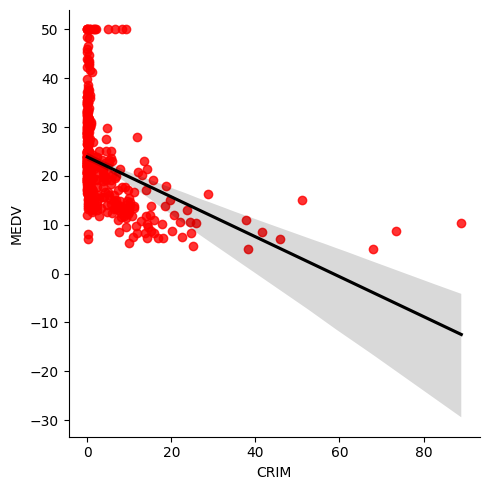

In [ ]:
sns.lmplot(x='CRIM',y='MEDV', data=housing_df,
           scatter_kws = {'color':'red'}, line_kws={'color':'black'})

### Multiple Regression

In [12]:
statsOLSModel_all = ols('MEDV ~ CRIM+ZN+INDUS+CHAS+NOX+RM+AGE+DIS+RAD+TAX+PTRATIO+B+LSTAT',
                        data=housing_df)
statsOLSModel_all

In [13]:
statsOLSModel_all_res = statsOLSModel_all.fit()
statsOLSModel_all_res

In [14]:
print(statsOLSModel_all_res.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.767
Model:                            OLS   Adj. R-squared:                  0.759
Method:                 Least Squares   F-statistic:                     96.29
Date:                Sun, 15 Nov 2026   Prob (F-statistic):          1.75e-111
Time:                        11:29:32   Log-Likelihood:                -1143.4
No. Observations:                 394   AIC:                             2315.
Df Residuals:                     380   BIC:                             2370.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     32.6801      5.681      5.752      0.0

In [15]:
housing_df.corr()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
CRIM,1.000000,-0.191178,0.401863,-0.054355,0.417130,-0.219150,0.354342,-0.374166,0.624765,0.580595,0.281110,-0.381411,0.444943,-0.391363
ZN,-0.191178,1.000000,-0.531871,-0.037229,-0.513704,0.320800,-0.563801,0.656739,-0.310919,-0.312371,-0.414046,0.171303,-0.414193,0.373136
INDUS,0.401863,-0.531871,1.000000,0.059859,0.764866,-0.390234,0.638431,-0.711709,0.604533,0.731055,0.390954,-0.360532,0.590690,-0.481772
CHAS,-0.054355,-0.037229,0.059859,1.000000,0.075097,0.104885,0.078831,-0.093971,0.001468,-0.032304,-0.111304,0.051264,-0.047424,0.181391
NOX,0.417130,-0.513704,0.764866,0.075097,1.000000,-0.302188,0.731548,-0.769230,0.611441,0.668023,0.188933,-0.380051,0.582641,-0.427321
RM,-0.219150,0.320800,-0.390234,0.104885,-0.302188,1.000000,-0.247337,0.205246,-0.209847,-0.292048,-0.355501,0.128069,-0.614339,0.695360
AGE,0.354342,-0.563801,0.638431,0.078831,0.731548,-0.247337,1.000000,-0.744844,0.458349,0.509114,0.269226,-0.275303,0.602891,-0.394656
DIS,-0.374166,0.656739,-0.711709,-0.093971,-0.769230,0.205246,-0.744844,1.000000,-0.494588,-0.534432,-0.232471,0.291512,-0.493328,0.249929
RAD,0.624765,-0.310919,0.604533,0.001468,0.611441,-0.209847,0.458349,-0.494588,1.000000,0.910228,0.464741,-0.444413,0.479541,-0.381626
TAX,0.580595,-0.312371,0.731055,-0.032304,0.668023,-0.292048,0.509114,-0.534432,0.910228,1.000000,0.460853,-0.441808,0.536110,-0.468536


In [16]:
statsOLSModel_all.exog

array([[1.0000e+00, 6.3200e-03, 1.8000e+01, ..., 1.5300e+01, 3.9690e+02,
        4.9800e+00],
       [1.0000e+00, 2.7310e-02, 0.0000e+00, ..., 1.7800e+01, 3.9690e+02,
        9.1400e+00],
       [1.0000e+00, 2.7290e-02, 0.0000e+00, ..., 1.7800e+01, 3.9283e+02,
        4.0300e+00],
       ...,
       [1.0000e+00, 4.5270e-02, 0.0000e+00, ..., 2.1000e+01, 3.9690e+02,
        9.0800e+00],
       [1.0000e+00, 6.0760e-02, 0.0000e+00, ..., 2.1000e+01, 3.9690e+02,
        5.6400e+00],
       [1.0000e+00, 1.0959e-01, 0.0000e+00, ..., 2.1000e+01, 3.9345e+02,
        6.4800e+00]], shape=(394, 14))

In [17]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
variance_inflation_factor(statsOLSModel_all.exog,1)

np.float64(1.7414043701695399)

In [18]:
all_vif_df = pd.DataFrame({'variable': column,
                           'VIF': variance_inflation_factor(statsOLSModel_all.exog, i)}
                          for i, column in enumerate(statsOLSModel_all.exog_names)
                          if column != 'Intercept')
all_vif_df

,variable,VIF
0,CRIM,1.741404
1,ZN,2.321843
2,INDUS,4.049690
3,CHAS,1.069182
4,NOX,4.495772
5,RM,2.107004
6,AGE,3.173844
7,DIS,3.827427
8,RAD,6.986683
9,TAX,8.651382


In [19]:
all_vif_df['VIF'].mean()

np.float64(3.4433439706985123)

In [20]:
model_vif = ols('MEDV ~ CRIM+ZN+INDUS+CHAS+NOX+RM+AGE+DIS+PTRATIO+B+LSTAT', data=housing_df)

vif_df = pd.DataFrame({'variable': column,
                       'VIF': variance_inflation_factor(model_vif.exog, i)}
                      for i, column in enumerate(model_vif.exog_names)
                      if column != 'Intercept')
vif_df

,variable,VIF
0,CRIM,1.455569
1,ZN,2.155963
2,INDUS,3.090276
3,CHAS,1.048445
4,NOX,3.892387
5,RM,2.046956
6,AGE,3.126951
7,DIS,3.825071
8,PTRATIO,1.542539
9,B,1.346292


In [21]:
vif_df['VIF'].mean()

np.float64(2.4240846075789237)

In [22]:
print(model_vif.fit().summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.757
Model:                            OLS   Adj. R-squared:                  0.750
Method:                 Least Squares   F-statistic:                     108.0
Date:                Sun, 15 Nov 2026   Prob (F-statistic):          6.29e-110
Time:                        11:29:48   Log-Likelihood:                -1152.1
No. Observations:                 394   AIC:                             2328.
Df Residuals:                     382   BIC:                             2376.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     26.0322      5.438      4.787      0.0

### Homoskedasticity

[Text(0.5, 1.0, 'Multiple Regression: Residuals vs. Fitted Values'),
 Text(0.5, 0, 'Fitted MEDV ($1,000s)'),
 Text(0, 0.5, 'Residuals ($1,000s)')]

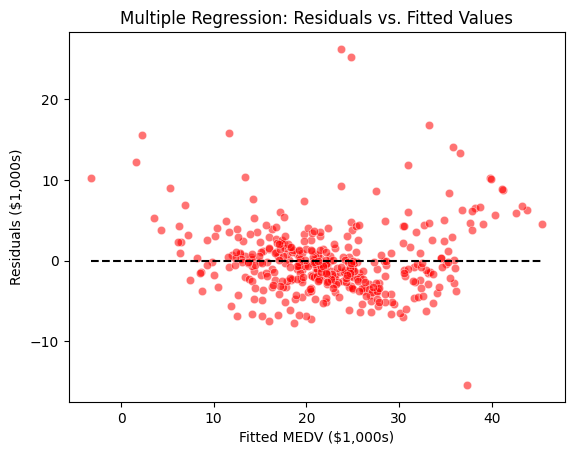

In [23]:
multiple_diag_df = pd.DataFrame({
    'Fitted MEDV': statsOLSModel_all_res.fittedvalues.to_numpy(),
    'Residuals': statsOLSModel_all_res.resid.to_numpy()
})

ax = sns.scatterplot(data=multiple_diag_df,
                     x='Fitted MEDV', y='Residuals',
                     color='red', alpha=0.55)

zero_df = pd.DataFrame({
    'Fitted MEDV': [multiple_diag_df['Fitted MEDV'].min(),
                    multiple_diag_df['Fitted MEDV'].max()],
    'Residuals': [0, 0]
})
sns.lineplot(data=zero_df, x='Fitted MEDV', y='Residuals',
             color='black', linestyle='--', ax=ax)
ax.set(title='Multiple Regression: Residuals vs. Fitted Values',
       xlabel='Fitted MEDV ($1,000s)', ylabel='Residuals ($1,000s)')

In [24]:
from statsmodels.stats.diagnostic import het_breuschpagan

lm_stat, lm_p, f_stat, f_p = het_breuschpagan(
    statsOLSModel_all_res.resid, statsOLSModel_all_res.model.exog
)
print(f'Breusch–Pagan LM statistic: {lm_stat:.3f}')
print(f'Breusch–Pagan p-value: {lm_p:.5g}')
print('Reject homoskedasticity at 5%?', lm_p < 0.05)

Breusch–Pagan LM statistic: 44.691
Breusch–Pagan p-value: 2.3559e-05
Reject homoskedasticity at 5%? True


The Breusch–Pagan test rejects the null hypothesis of homoskedasticity (p < 0.001), providing statistically significant evidence of heteroskedasticity. This suggests that conventional OLS standard errors may be unreliable. Therefore, heteroskedasticity-robust standard errors should be considered for statistical inference.

### Normality issue

In [ ]:
res_all_fix = ols('MEDV ~ CRIM+ZN+INDUS+CHAS+NOX+RM+AGE+DIS+PTRATIO+B+LSTAT',
                  data=housing_df).fit()

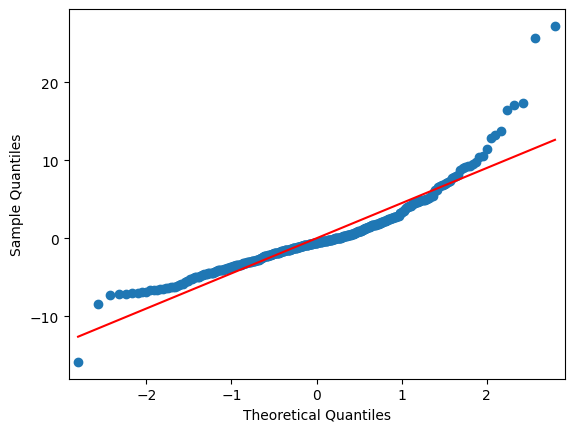

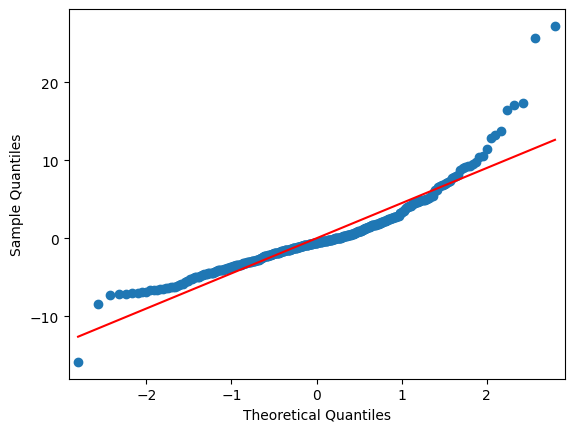

In [ ]:
import statsmodels.api as sm
sm.qqplot(res_all_fix.resid, line = 's')

### Practice

In [26]:
# Which variables are statistically significant at the 5% level?
practice_df = housing_df[
    ['MEDV', 'RM', 'CRIM', 'NOX', 'PTRATIO']
].dropna().copy()

# Model 1
practice_model_1 = ols(
    'MEDV ~ RM + CRIM',
    data=practice_df
).fit()
print(practice_model_1.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.540
Model:                            OLS   Adj. R-squared:                  0.538
Method:                 Least Squares   F-statistic:                     283.4
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           3.83e-82
Time:                        11:45:26   Log-Likelihood:                -1574.0
No. Observations:                 486   AIC:                             3154.
Df Residuals:                     483   BIC:                             3166.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -28.3134      2.608    -10.856      0.0

In [27]:
# Model 2
practice_model_2 = ols(
    'MEDV ~ RM + CRIM + NOX + PTRATIO',
    data=practice_df
).fit()
print(practice_model_2.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.620
Model:                            OLS   Adj. R-squared:                  0.617
Method:                 Least Squares   F-statistic:                     196.2
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           1.33e-99
Time:                        11:45:32   Log-Likelihood:                -1527.5
No. Observations:                 486   AIC:                             3065.
Df Residuals:                     481   BIC:                             3086.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.8177      4.388      2.010      0.0

In both models, all independent variables are statistically significant at the 5% level (p < 0.001).

In Model 1, RM (β = 8.2338) is positively associated with median housing values, while CRIM (β = −0.2628) is negatively associated with them.

In Model 2, all four variables remain statistically significant. RM (β = 6.7209) has a positive coefficient, whereas CRIM (β = −0.1355), NOX (β = −14.0023), and PTRATIO (β = −1.0993) have negative coefficients.

Notably, after including NOX and PTRATIO in Model 2, the estimated coefficients of RM and CRIM decrease in magnitude. This suggests that some of the associations observed in Model 1 may be related to differences in air pollution and school conditions.

Overall, both models indicate statistically significant relationships between housing characteristics, neighborhood conditions, and median housing values. However, statistical significance does not necessarily imply causality.

In [28]:
# Which model would you prefer, and why?
comparison = pd.DataFrame({
    'Model': ['Model 1', 'Model 2'],
    'Adjusted R-squared': [
        practice_model_1.rsquared_adj,
        practice_model_2.rsquared_adj
    ],
    'AIC': [
        practice_model_1.aic,
        practice_model_2.aic
    ],
    'BIC': [
        practice_model_1.bic,
        practice_model_2.bic
    ]
})
comparison


,Model,Adjusted R-squared,AIC,BIC
0,Model 1,0.537977,3153.919170,3166.477796
1,Model 2,0.616804,3064.987322,3085.918365


Model 2 is preferred because it demonstrates better model fit, even after accounting for additional model complexity.

Model 2 has a higher adjusted R-squared (0.617 vs. 0.538), indicating that it explains a greater proportion of variation in median housing values after adjusting for the number of predictors. Additionally, Model 2 has lower AIC (3064.99 vs. 3153.99) and BIC (3085.92 vs. 3166.48), suggesting that the improvement in model fit outweighs the penalty for including additional variables.

Overall, Model 2 provides a better balance between explanatory power and model complexity, making it the preferred model based on these criteria.

<Axes: xlabel='Fitted', ylabel='Residuals'>

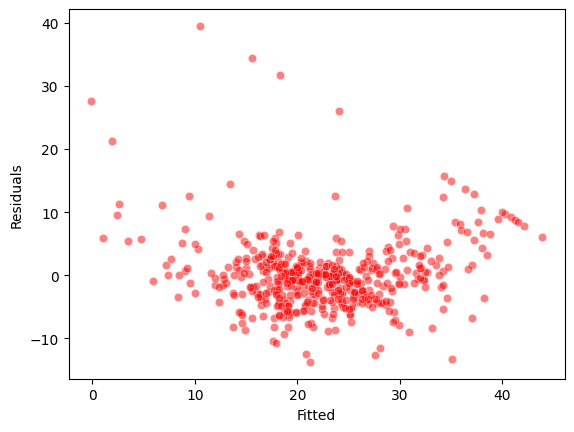

In [29]:
# Create a residuals-versus-fitted-values plot for Model 2 using Seaborn.
# Conduct a Breusch–Pagan test and interpret the results.
# Residuals vs. Fitted Values
residual_df = pd.DataFrame({
    'Fitted': practice_model_2.fittedvalues,
    'Residuals': practice_model_2.resid
})

sns.scatterplot(
    data=residual_df,
    x='Fitted',
    y='Residuals',
    color='red',
    alpha=0.5
)

In [30]:
# Breusch–Pagan Test
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(
    practice_model_2.resid,
    practice_model_2.model.exog
)

print('LM statistic:', bp_test[0])
print('p-value:', bp_test[1])

LM statistic: 7.323660039976741
p-value: 0.11974127077101746


The residual plot shows some systematic patterns and several outliers, suggesting potential model misspecification. However, the Breusch–Pagan test produces an LM statistic of 7.324 and a p-value of 0.120, which is greater than the 5% significance level.

Therefore, we fail to reject the null hypothesis of homoskedasticity, indicating that there is insufficient statistical evidence of heteroskedasticity in Model 2.

Although the homoskedasticity assumption is not rejected, the residual patterns suggest that further model diagnostics may still be necessary.

In [ ]:
# Summarize your findings in 3–5 sentences. Can the regression results be interpreted as causal relationships?

Both models show statistically significant relationships between housing characteristics, neighborhood conditions, and median housing values. Model 2 provides a better fit, with a higher adjusted R-squared and lower AIC and BIC values, suggesting that including additional variables improves the model. Although the Breusch–Pagan test does not reject the homoskedasticity assumption, the residual plot suggests potential model misspecification. However, these results cannot be interpreted as causal relationships because omitted variables, reverse causality, and other sources of endogeneity may affect the estimated coefficients.